# BALLADEER — 03. Preprocesamiento (pasos 2.1–2.10, 3.1, 3.2, la partición de 4.2 y la asignación de 4.3 con la separabilidad de 5.1)

Plan experimental v40 (`experiments-plan-experimental-mil-creda-sobre-balladeer-v40.md`), secciones 2.1–2.10, 3.1, 3.2, 4.2, 4.3, 4.6 y 5.1.

**Este cuaderno es el punto de entrada reproducible del preprocesamiento.** Ejecutado de arriba abajo sobre un clon limpio del repositorio, con solo los datos crudos en `MIL-CREDA/Data/raw/`, toma el release crudo y produce `MIL-CREDA/Data/processed/` completo: un archivo por registro, el manifiesto, las tablas de flujo y los cruces. Al terminar congela la partición en cuatro folds sobre los sujetos que sobreviven (`MIL-CREDA/Partition/folds_4.json`, la vigente; la de cinco folds, `folds.json`, se conserva sin tocar) y escribe el hash de cada archivo procesado (`MIL-CREDA/Manifests/processed_sha256.csv`); los dos van al repositorio, los datos no. Después muestra las estadísticas y las figuras. No lee ninguna salida de la auditoría ni ningún archivo fuera del control de versiones, salvo los datos crudos: cada exclusión y cada marca se recalcula desde el crudo con las funciones del paquete.

| Paso | Módulo | Qué hace |
|---|---|---|
| todo el flujo | `preprocess` | verifica el crudo, borra el caché si `REBUILD`, corre el pipeline y escribe las salidas |
| 2.1, 2.7 | `preprocess_filter` | solo canales de cuero cabelludo (29 CGX, 14 Emotiv), banda 0,2–45 Hz sobre la grabación continua y **después** remuestreo a 128 Hz |
| 3.1, 2.3–2.5, 2.8 | `windows` | ventanas de 4 s sin solape (512 muestras), sin la primera ni la parcial final; marcas por ventana como datos laterales |
| 2.2, 2.4, 2.5, 2.10, 3.2 | `exclusions` | los tres defectos duros, las dos exclusiones por diseño (indeterminados y EPOC+), el piso de bolsa, la tabla de flujo y los cruces |
| 4.2 | `partition` | cuatro folds estratificados por etiqueta y sexo, sus rotaciones, la huella y el hash; recalcula y compara en cada corrida |
| 3.2, 4.3, 4.6, 5.1, 6.2 | `bag_data`, `assignment`, `separability` | las bolsas, la asignación de dominio por transferencia con la sonda, el agrupado por par y la elegibilidad, y la separabilidad re-medida con la regla núcleo/control |

El mismo pipeline corre sin cuaderno desde la raíz del repositorio:

```
PYTHONPATH=src .venv/bin/python -m MIL_CREDA_EEG.preprocess \
    --raw "MIL-CREDA/Data/raw/BALLADEER ADHD DATASET" --out MIL-CREDA/Data/processed
```

que escribe la partición y el manifiesto de hashes en las mismas rutas que este cuaderno.

La señal no se corrige: no hay re-referencia, ni ICA, ni interpolación. Las marcas no tocan la señal.

In [1]:
#!/usr/bin/env python3
"""The first code cell of every notebook a job may run — copied byte for byte.

One question, answered once: WHERE IS THE REPOSITORY THIS NOTEBOOK RUNS
AGAINST. Every later cell reads `ROOT` and none of them asks again.

Opened by a person on their own machine, this answers it exactly the way
these notebooks always have. A notebook lives at `<repo>/<Name>/Notebooks/`,
so the repository is two directories above the working directory. Nothing was
handed over, nothing is checked, and the behaviour is unchanged.

Started by a runner on a remote worker, it does not answer it by looking
around. The runner exports the directory it cloned the pinned commit into and
the commit it pinned; this cell reads both, and PROVES the checkout is at that
commit before returning it.

Guessing is the whole reason this cell exists. Under the runner the kernel's
working directory is the runner's own and the clone sits one level inside it,
so two directories up is two levels ABOVE the working directory — a directory
that EXISTS on any worker. The path resolves, the insert succeeds, and the run
dies later with a missing module naming a package, never with the wrong root.
The one fact worth having is the one the failure never mentions.

Three refusals, and each one is a refusal rather than a fallback because this
is the path that spends metered quota:

- **Half a handoff** — one variable present and the other missing. Something
  built this environment and got it half right; that is precisely the state a
  fallback cannot tell apart from a laptop, and the fallback resolves a
  directory that exists everywhere.
- **A root that is not a checkout** — the declared directory is missing, or
  holds no readable `HEAD`. There is nothing to compare against, and an
  unproven root is what this cell was written to stop being acceptable.
- **A checkout at a different commit** — the declared commit and the one on
  disk disagree. A job that runs the wrong commit RUNS: it returns numbers
  shaped exactly like the right ones, and nothing downstream can tell.

Absent means LOCAL. It never means "work it out".

Importable and independently testable, the way the runner's own two cells
are: every function is pure and takes its environment and its working
directory as arguments, and only the last line — the binding a notebook cell
exists to perform — reads the real ones.
"""
import os
from pathlib import Path

#: The directory a runner cloned the pinned commit into. Forge-owned and
#: deliberately generic: this is the contract between a runner and the
#: notebook it starts, not a name borrowed from any one repository.
CLONE_ROOT_ENV = "FORGE_CLONE_ROOT"

#: The commit that clone was pinned to, exported beside it so this cell can
#: check rather than trust. A root on its own would only move the guess one
#: step: a directory handed over is still a directory nobody proved.
CLONE_COMMIT_ENV = "FORGE_CLONE_COMMIT"

#: How far above a notebook's own directory the repository sits when nobody
#: hands anything over: `<repo>/<Name>/Notebooks` -> `<repo>`.
LOCAL_ROOT_DEPTH = 1


def head_commit(root):
    """The commit `root`'s `HEAD` names, read straight out of `.git`.

    No subprocess, deliberately. A notebook cell that shells out needs a git
    binary on a worker's PATH that nothing here declared, and every checker
    that reads these notebooks then has to decide whether running the cell is
    safe — a cell that binds the repository is the last one that may be
    skipped for that reason.

    A pinned checkout is detached: the runner fetches a commit and checks out
    what it fetched, never a branch, so `HEAD` holds the raw commit and this
    is a one-line read. A symbolic `HEAD` is resolved anyway — through the
    loose ref and then `packed-refs` — so pointing these variables at an
    ordinary checkout gets an answer instead of a refusal that would be about
    the file format rather than about the commit.

    Returns `None` when there is nothing to read. The caller turns that into
    a refusal; this function never decides.
    """
    git = Path(root) / ".git"
    if git.is_file():
        pointer = git.read_text(encoding="utf-8").strip()
        if not pointer.startswith("gitdir:"):
            return None
        git = Path(root) / pointer[len("gitdir:"):].strip()
    if not git.is_dir():
        return None
    head = git / "HEAD"
    if not head.is_file():
        return None
    text = head.read_text(encoding="utf-8").strip()
    if not text.startswith("ref:"):
        return text or None
    ref = text[len("ref:"):].strip()
    loose = git / ref
    if loose.is_file():
        return loose.read_text(encoding="utf-8").strip() or None
    packed = git / "packed-refs"
    if packed.is_file():
        for line in packed.read_text(encoding="utf-8").splitlines():
            if line.startswith("#") or line.startswith("^"):
                continue
            fields = line.split()
            if len(fields) == 2 and fields[1] == ref:
                return fields[0]
    return None


def resolve_repository_root(environ=None, cwd=None, head_reader=head_commit):
    """The repository this notebook runs against, or a refusal saying why.

    `environ` and `cwd` are arguments so the whole decision can be driven
    without a kernel, a clone or a worker; the binding at the bottom of this
    cell passes the real ones.
    """
    environ = os.environ if environ is None else environ
    here = Path.cwd() if cwd is None else Path(cwd)
    declared_root = environ.get(CLONE_ROOT_ENV)
    declared_commit = environ.get(CLONE_COMMIT_ENV)

    if not declared_root and not declared_commit:
        return here.parents[LOCAL_ROOT_DEPTH]

    if not declared_root or not declared_commit:
        raise RuntimeError(
            "half a handoff: {0}={1!r} and {2}={3!r}. Both name the pinned "
            "checkout this notebook must run against, and one without the "
            "other is an environment somebody built and got half right. "
            "Falling back to the local layout here would resolve a directory "
            "that exists on any machine and is not this repository.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))

    root = Path(declared_root)
    found = head_reader(root) if root.is_dir() else None
    if found is None:
        raise RuntimeError(
            "{0}={1!r} is not a readable checkout: no commit could be read "
            "from its HEAD. {2} declares {3!r}, and there is nothing here to "
            "check it against.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))
    if found.lower() != declared_commit.lower():
        raise RuntimeError(
            "the checkout at {0}={1!r} is at commit {2}, and {3} declares "
            "{4}. A job that runs a commit nobody asked for RUNS, and the "
            "numbers it returns look exactly like the right ones.".format(
                CLONE_ROOT_ENV, declared_root, found,
                CLONE_COMMIT_ENV, declared_commit))
    return root


ROOT = resolve_repository_root()


In [2]:
# El repositorio lo resolvió la celda de arriba; ésta sólo lo usa.
import sys
from pathlib import Path

REPOSITORY = ROOT
sys.path.insert(0, str(REPOSITORY / "src"))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import welch

from MIL_CREDA_EEG import (audit_channels, audit_contact, audit_plots, exclusions, inventory,
                           modality, partition, preprocess, preprocess_filter, windows)

%matplotlib inline
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

venv = (REPOSITORY / ".venv").resolve()
print("intérprete:", Path(sys.executable).relative_to(REPOSITORY) if Path(sys.executable).is_relative_to(REPOSITORY) else sys.executable)
assert Path(sys.prefix).resolve() == venv, (
    "el kernel no es el entorno .venv de este repositorio; ejecutá el cuaderno con "
    "<repositorio>/.venv/bin/python")

intérprete: .venv/bin/python


## Parámetros

Todos los parámetros del preprocesamiento, con la sección del plan de la que salen. Viven en los módulos (la misma fuente que leen las pruebas); esta celda los declara y comprueba que el paquete usa exactamente estos valores, así que un cambio en uno sin el otro detiene el cuaderno. El preprocesamiento no tiene ninguna parte aleatoria; la única semilla es la de la partición (4.2), que no sortea nada: ordena cada estrato por `sha256("<semilla>:<sujeto>")`.

* `REBUILD = True` borra el caché por registro bajo `MIL-CREDA/Data/processed/` (solo los archivos que este pipeline escribe) y recalcula todo desde el crudo. Con `False` reutiliza lo ya calculado.
* `VERIFY_ZIP_MD5 = True` comprueba el MD5 del zip publicado si está en `MIL-CREDA/Data/`.
* `REGENERATE_PARTITION = False`: la partición congelada se recalcula y se compara; si difiere, el cuaderno se detiene diciendo qué cambió. Regenerarla exige `REGENERATE_PARTITION = True` **y** un `NEW_PARTITION_NAME` nuevo; la anterior nunca se sobrescribe.

In [3]:
REBUILD = True
VERIFY_ZIP_MD5 = True
WORKERS = 4
REGENERATE_PARTITION = False
NEW_PARTITION_NAME = None      # p. ej. "folds_4-v2.json", solo con REGENERATE_PARTITION

PARAMETERS = {
    # nombre: (valor, sección del plan, valor que usa el paquete)
    "banda (Hz)": ((0.2, 45.0), "2.7", audit_channels.BAND),
    "tasa común (Hz)": (128.0, "2.7", preprocess_filter.TARGET_RATE),
    "ventana (s)": (4.0, "3.1", windows.WINDOW_S),
    "muestras por ventana": (512, "3.1", windows.WINDOW_SAMPLES),
    "ventanas iniciales descartadas": (1, "2.7", windows.DISCARDED_LEADING),
    "nivel CQ máximo (contacto bueno)": (4.0, "2.5", audit_contact.CQ_TOP),
    "mayoría estricta de la regla de contacto": (0.5, "2.5", audit_contact.RULE_MAJORITY),
    "mayoría estricta de canales muertos (registro sin EEG)": (0.5, "2.4", exclusions.NO_EEG_MAJORITY),
    "rieles Emotiv (µV)": ((0.0, 8401.922852), "2.4", audit_channels.RAILS["EMOTIV"]),
    "rieles CGX (µV)": ((-833333.0, 833333.0), "2.4", audit_channels.RAILS["CGX"]),
    "modelo excluido por diseño": ("EPOCPLUS", "2.10", exclusions.EXCLUDED_DEVICE),
    "piso de bolsa (ventanas útiles)": (68, "3.2", windows.BAG_FLOOR),
    "folds": (4, "4.2", partition.N_FOLDS),
    "semilla de partición": (20261025, "4.2", partition.PARTITION_SEED),
    "estratos de la partición": (("label", "sex"), "4.2", partition.STRATA),
}
for name, (value, section, used) in PARAMETERS.items():
    assert tuple(np.atleast_1d(value)) == tuple(np.atleast_1d(used)), (name, value, used)
pd.DataFrame([{"parámetro": k, "valor": v[0], "sección": v[1]} for k, v in PARAMETERS.items()])

,parámetro,valor,sección
0,banda (Hz),"(0.2, 45.0)",2.7
1,tasa común (Hz),128.0,2.7
2,ventana (s),4.0,3.1
3,muestras por ventana,512,3.1
4,ventanas iniciales descartadas,1,2.7
5,nivel CQ máximo (contacto bueno),4.0,2.5
6,mayoría estricta de la regla de contacto,0.5,2.5
7,mayoría estricta de canales muertos (registro ...,0.5,2.4
8,rieles Emotiv (µV),"(0.0, 8401.922852)",2.4
9,rieles CGX (µV),"(-833333.0, 833333.0)",2.4


## Fuente de los datos

El release crudo es el publicado en Figshare: DOI [10.6084/m9.figshare.28676042](https://doi.org/10.6084/m9.figshare.28676042), archivo `BALLADEER ADHD DATASET.zip`, MD5 `c7e7b5d57855ada4a380f667d1a5cf85`, descomprimido en `MIL-CREDA/Data/raw/` (queda `MIL-CREDA/Data/raw/BALLADEER ADHD DATASET/`). La celda siguiente comprueba que la carpeta exista y tenga la estructura publicada (158 carpetas de sujeto `UB*` y `users_demographics.json`) y se detiene con un mensaje claro si no. Si el zip está en `MIL-CREDA/Data/`, verifica también su MD5.

In [4]:
RAW = REPOSITORY / inventory.RAW_RELATIVE
OUT = REPOSITORY / "MIL-CREDA" / "Data" / "processed"
FIG = REPOSITORY / "MIL-CREDA" / "Results" / "preprocess" / "figures"
PARTITION = REPOSITORY / preprocess.PARTITION_RELATIVE
SHA_MANIFEST = REPOSITORY / preprocess.SHA_MANIFEST_RELATIVE

raw_info = preprocess.check_raw(RAW)
print("crudo:", RAW.relative_to(REPOSITORY), raw_info)
if VERIFY_ZIP_MD5:
    print("zip:", preprocess.check_zip(RAW.parent.parent))

crudo: MIL-CREDA/Data/raw/BALLADEER ADHD DATASET {'subjects': 158, 'eeg_records': 683, 'by_device': {'CGX': 420, 'EPOCPLUS': 118, 'EPOCX': 145}}


zip: {'zip': 'BALLADEER_ADHD_DATASET.zip', 'md5': 'c7e7b5d57855ada4a380f667d1a5cf85', 'verified': True}


## Producir `MIL-CREDA/Data/processed/` desde el crudo

Una sola pasada: cada registro se lee una vez, se decide su exclusión y, si se conserva, se escriben sus ventanas y marcas. Al terminar se congela (o se comprueba) la partición y se escribe el manifiesto de hashes. Con `REBUILD = True` y cuatro procesos tarda del orden de veinte minutos sobre los 58 GB.

In [5]:
built = preprocess.build_processed(RAW, OUT, workers=WORKERS, rebuild=REBUILD,
                                   partition_path=PARTITION, sha_manifest_path=SHA_MANIFEST,
                                   regenerate_partition=REGENERATE_PARTITION,
                                   new_partition_name=NEW_PARTITION_NAME)
manifest = built["manifest"]
outputs = built
print("caché borrado:", built["cleared"], "archivos")
print(len(manifest), "registros;", int(manifest["excluded"].sum()), "excluidos;",
      int(manifest["n_windows"].sum()), "ventanas conservadas")
print("salidas:", sorted(p.name for p in OUT.iterdir()))
print("partición:", built["partition"]["status"], built["partition"]["path"].relative_to(REPOSITORY),
      built["partition"]["doc"]["partition_sha256"])
print("manifiesto de hashes:", SHA_MANIFEST.relative_to(REPOSITORY), len(built["sha_manifest"]), "archivos")


caché borrado: 1177 archivos
683 registros; 193 excluidos; 66393 ventanas conservadas
salidas: ['exclusion_crosses.csv', 'flow_CGX.csv', 'flow_EMOTIV.csv', 'manifest.csv', 'records', 'signals']
partición: unchanged MIL-CREDA/Partition/folds_4.json abc9012bad78eaaa542c08a1e38e2f35d110e00f33739d76853624297d8735d1
manifiesto de hashes: MIL-CREDA/Manifests/processed_sha256.csv 1177 archivos


## 2.1 y 2.7 — Qué entra a la señal y en qué orden se transforma

Entran solo los canales de cuero cabelludo, por nombre y en el orden canónico de `modality`: 29 en CGX y 14 en Emotiv. A2, los dos externos bipolares, el acelerómetro, los disparos, la batería y las métricas propietarias de Emotiv nunca entran. El puntaje de foco (`PM.Focus.Scaled`, o `PM.Attention.Scaled` en las exportaciones más nuevas) se guarda aparte como mediana por ventana, para el contraste opcional de la sección 6.1.

Los registros EPOC+ salen por diseño (2.10), así que aquí solo se muestran CGX y EPOC X.

El orden es una restricción: primero el pasa-banda 0,2–45 Hz (el mismo Butterworth de orden 4 y fase cero que usó la auditoría), sobre la grabación continua, y después el remuestreo polifásico a 128 Hz (CGX 500 → 128 con factor 32/125; EPOC+ a 256 → 128 con 1/2; los registros a 128 Hz pasan sin cambio).

In [6]:
channels = {}
for device in ("CGX", "EPOCX"):
    rid = manifest.loc[(manifest.device == device) & ~manifest.excluded, "npz"].iloc[0]
    with np.load(OUT / rid) as z:
        channels[device] = list(z["channels"])
for device, chs in channels.items():
    extras = sorted(set(chs) & {"A2", "ExG 1", "ExG 2"})
    print(f"{device}: {len(chs)} canales; extras presentes: {extras or 'ninguno'}")
assert channels["CGX"] == list(modality.CGX_CHANNELS)
assert channels["EPOCX"] == list(modality.EMOTIV_CHANNELS)
assert not (~manifest.excluded & (manifest.device == "EPOCPLUS")).any()
print("columna de foco leída:", manifest.loc[(manifest.family == "EMOTIV") & ~manifest.excluded,
                                           "focus_column"].value_counts(dropna=False).to_dict())


CGX: 29 canales; extras presentes: ninguno
EPOCX: 14 canales; extras presentes: ninguno
columna de foco leída: {'PM.Focus.Scaled': 68, 'PM.Attention.Scaled': 52, nan: 1}


## Antes y después: el espectro de un registro por dispositivo

Un registro de ejemplo por dispositivo conservado (CGX y EPOC X; EPOC+ sale por diseño): el crudo a su tasa nativa contra el procesado a 128 Hz (todas sus ventanas conservadas, una detrás de otra). Las líneas marcan el borde de 45 Hz y la nueva frecuencia de Nyquist, 64 Hz. Ojo: 45 Hz es el punto de −6 dB de un filtro de fase cero de orden 4, no una pared; la red de 50 Hz conserva una fracción de su potencia (tabla de razones debajo de las figuras).

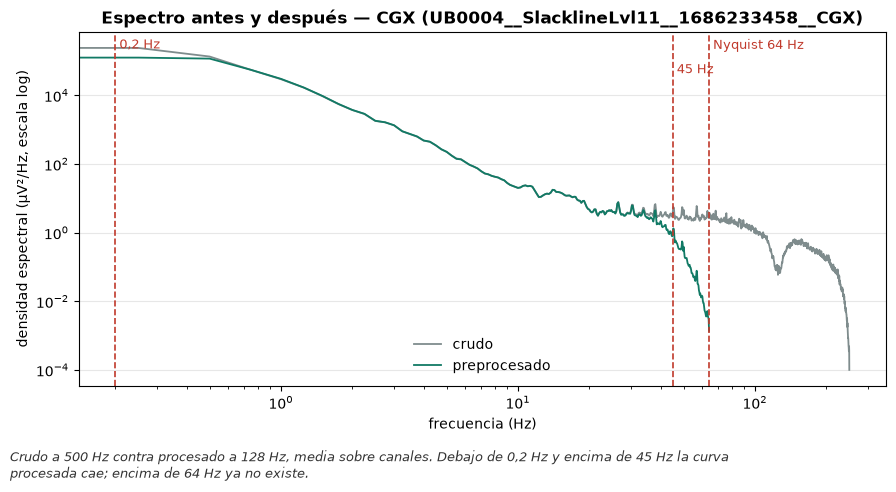

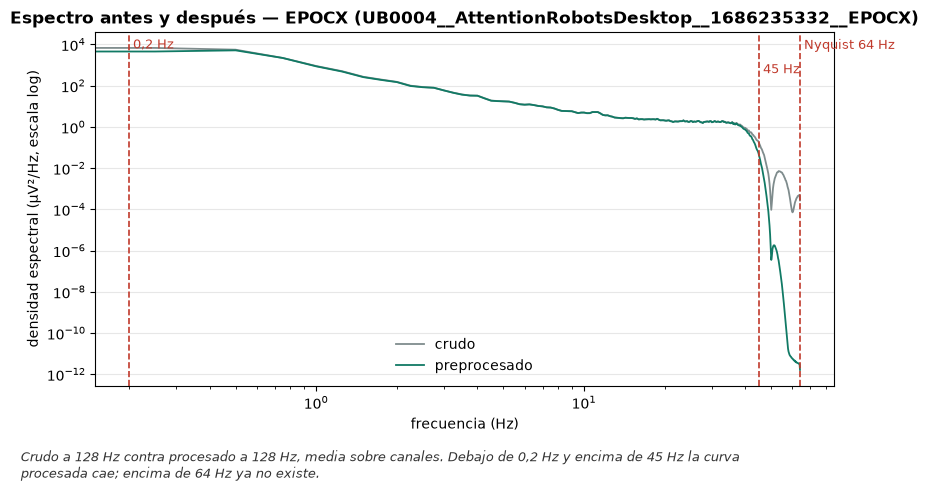

,ejemplo,tasa cruda,potencia 8–12 Hz (procesada/cruda),potencia 49–51 Hz,potencia 55–60 Hz
0,CGX,500.0,1.0019,0.0878,0.0112
1,EPOCX,128.0,1.0008,0.0069,0.0000


In [7]:
def psd_raw(record_id: str):
    row = inventory.eeg_records(inventory.build_index(RAW)).set_index("record_id").loc[record_id]
    record = modality.read_record(RAW / row["path"])
    scalp, _ = preprocess_filter.scalp_signal(record)
    rate = float(record.nominal_rate)
    f, p = welch(scalp - scalp.mean(axis=0), fs=rate, nperseg=int(rate * 4), axis=0)
    return f, p.mean(axis=1), rate

def psd_processed(npz: str):
    with np.load(OUT / npz) as z:
        x = np.concatenate(list(z["signal"]), axis=1)      # canales x muestras
    f, p = welch(x - x.mean(axis=1, keepdims=True), fs=128.0, nperseg=512, axis=1)
    return f, p.mean(axis=0)

def band_ratio(f_raw, p_raw, f_pro, p_pro, lo, hi):
    a = p_raw[(f_raw >= lo) & (f_raw <= hi)].mean()
    b = p_pro[(f_pro >= lo) & (f_pro <= hi)].mean()
    return b / a

# Per device, the record with the smallest fraction of integrity-marked windows.
kept = manifest[~manifest.excluded].assign(
    marked=lambda t: t.windows_integrity_marked.fillna(0) / t.n_windows)
pick = lambda rows: rows.sort_values(["marked", "record_id"]).iloc[0]
examples = {d: pick(kept[kept.device == d]) for d in ("CGX", "EPOCX")}
ratios = []
for name, row in examples.items():
    f_raw, p_raw, rate = psd_raw(row["record_id"])
    f_pro, p_pro = psd_processed(row["npz"])
    fig = audit_plots.psd_before_after(
        (f_raw, p_raw), (f_pro, p_pro), f"Espectro antes y después — {name} ({row['record_id']})",
        f"Crudo a {rate:.0f} Hz contra procesado a 128 Hz, media sobre canales. Debajo de 0,2 Hz "
        "y encima de 45 Hz la curva procesada cae; encima de 64 Hz ya no existe.",
        lines={"0,2 Hz": 0.2, "45 Hz": 45.0, "Nyquist 64 Hz": 64.0})
    fig.axes[0].set_xscale("log")
    audit_plots.save(fig, f"03_2.7_psd_{name.split()[0]}", FIG); plt.show()
    ratios.append({"ejemplo": name, "tasa cruda": rate,
                   "potencia 8–12 Hz (procesada/cruda)": band_ratio(f_raw, p_raw, f_pro, p_pro, 8, 12),
                   "potencia 49–51 Hz": band_ratio(f_raw, p_raw, f_pro, p_pro, 49, 51),
                   "potencia 55–60 Hz": band_ratio(f_raw, p_raw, f_pro, p_pro, 55, 60)})
pd.DataFrame(ratios).round(4)

## 3.1 — Ventanas por registro

Ventanas de 4 s sin solape: 512 muestras a 128 Hz. Cada ventana procesada contiene exactamente las muestras de un bloque de muestras crudas de 4 s (2000 en CGX, 512 en EPOC X a 128 Hz), la misma convención que usó la auditoría. Se descarta la primera ventana de cada registro (el transitorio del filtro, sección 2.7) y la parcial final (sección 3.1).

ventanas totales conservadas: 66393


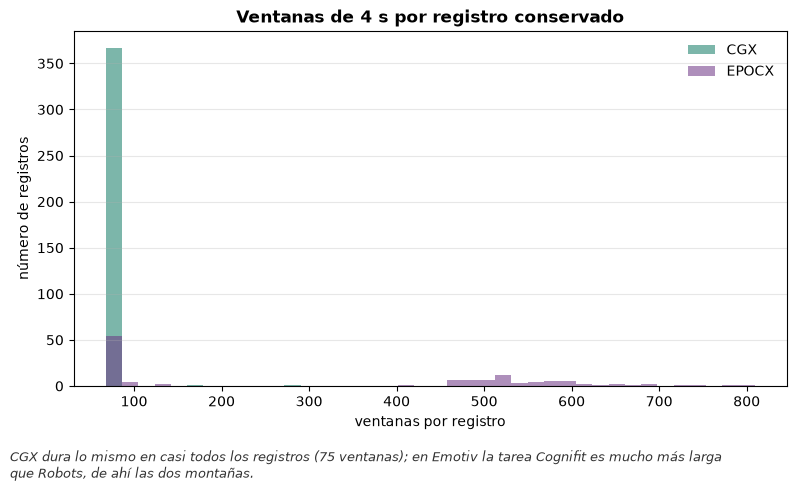

,count,min,50%,max,ventanas en total,descartadas (primera)
device,,,,,,
CGX,369.0,75.0,75.0,282.0,28028,369
EPOCX,121.0,68.0,406.0,809.0,38365,121


In [8]:
kept = manifest[~manifest.excluded]
table = kept.groupby("device")["n_windows"].describe()[["count", "min", "50%", "max"]]
table["ventanas en total"] = kept.groupby("device")["n_windows"].sum()
table["descartadas (primera)"] = kept.groupby("device").size()
print("ventanas totales conservadas:", int(kept["n_windows"].sum()))
fig = audit_plots.hist(None, "Ventanas de 4 s por registro conservado", "ventanas por registro",
    caption="CGX dura lo mismo en casi todos los registros (75 ventanas); en Emotiv la tarea "
    "Cognifit es mucho más larga que Robots, de ahí las dos montañas.",
    groups={d: kept.loc[kept.device == d, "n_windows"] for d in ("CGX", "EPOCX")},
    bins=40)
audit_plots.save(fig, "03_3.1_ventanas_por_registro", FIG); plt.show()
table

In [9]:
by_condition = kept.pivot_table(index="condition", values="n_windows",
                                aggfunc=["count", "median", "sum"])
by_condition.columns = ["registros", "mediana de ventanas", "ventanas"]
by_condition

,registros,mediana de ventanas,ventanas
condition,,,
Cognifit/EMOTIV,61,529.0,33821
Robots/EMOTIV,60,72.0,4544
Slackline-L1/CGX,123,75.0,9241
Slackline-L11/CGX,123,75.0,9546
Slackline-L6/CGX,123,75.0,9241


## 2.3, 2.4, 2.5 y 2.8 — Marcas por ventana

Las marcas son datos laterales y no tocan la señal (hay una prueba que lo fija). Cada una se calcula con la misma función que usó la auditoría, de modo que un registro marcado allí queda marcado igual aquí:

* **integridad** (2.3): alguna muestra perdida o interpolada en la ventana; un hueco más largo que una ventana marca las ventanas que toca;
* **plano / saturado** (2.4): por canal, varianza cero en la ventana o alguna muestra en el riel del dispositivo;
* **contacto** (2.5, solo Emotiv): por canal, mediana de `CQ` en la ventana por debajo del nivel 4;
* **ocular** (2.8): pico a pico frontal y razón 0,5–4 Hz frontal/posterior, como valores, sin corte.

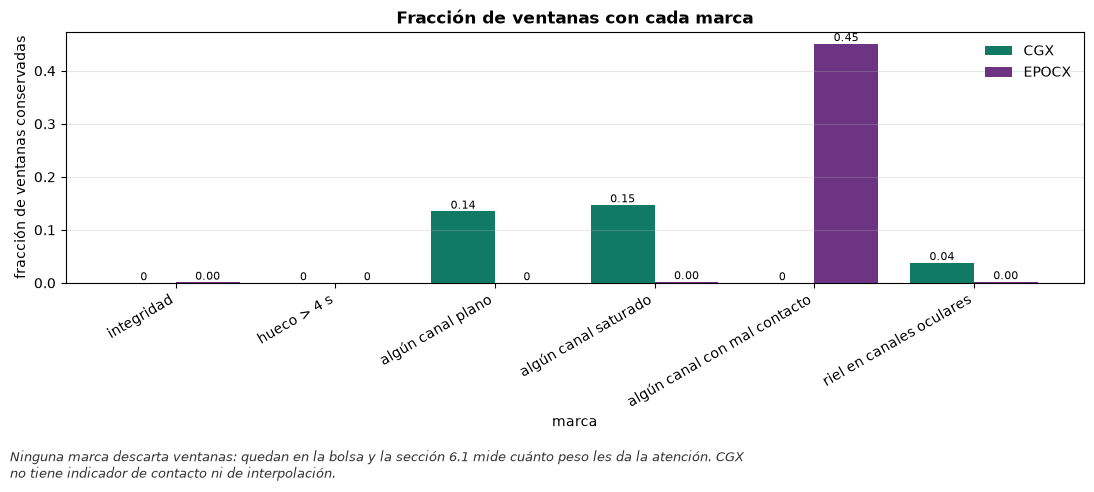

,n_windows,windows_integrity_marked,windows_long_gap,windows_any_flat,windows_any_saturated,windows_any_contact_bad,windows_rail_ocular
device,,,,,,,
CGX,28028,0.0,0.0,3797.0,4108.0,0.0,1073.0
EPOCX,38365,51.0,1.0,0.0,72.0,17311.0,63.0


In [10]:
marks = kept.groupby("device")[["n_windows", "windows_integrity_marked", "windows_long_gap",
                                "windows_any_flat", "windows_any_saturated",
                                "windows_any_contact_bad", "windows_rail_ocular"]].sum()
fractions = marks.drop(columns="n_windows").div(marks["n_windows"], axis=0)
fractions.columns = ["integridad", "hueco > 4 s", "algún canal plano", "algún canal saturado",
                     "algún canal con mal contacto", "riel en canales oculares"]
fig = audit_plots.grouped_bar(fractions.T.round(3), "Fracción de ventanas con cada marca",
    "marca", "fracción de ventanas conservadas",
    "Ninguna marca descarta ventanas: quedan en la bolsa y la sección 6.1 mide cuánto peso les da "
    "la atención. CGX no tiene indicador de contacto ni de interpolación.", figsize=(11, 4.5))
audit_plots.save(fig, "03_marcas_por_ventana", FIG); plt.show()
marks

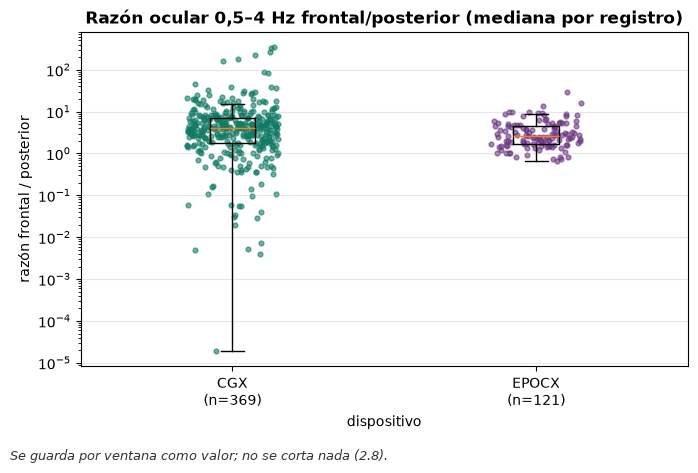

In [11]:
fig = audit_plots.box_by_group(
    {d: kept.loc[kept.device == d, "low_ratio_median"] for d in ("CGX", "EPOCX")},
    "Razón ocular 0,5–4 Hz frontal/posterior (mediana por registro)", "dispositivo",
    "razón frontal / posterior", "Se guarda por ventana como valor; no se corta nada (2.8).",
    log_y=True)
audit_plots.save(fig, "03_2.8_razon_ocular", FIG); plt.show()

## 2.2, 2.4, 2.5, 2.10 y 3.2 — Exclusiones y tabla de flujo

Tres reglas son defectos duros del registro: la tasa (2.2), el registro sin EEG (2.4: más de la mitad de sus canales planos o saturados en todas sus ventanas) y la regla de contacto por mayoría (2.5). Después vienen las dos exclusiones por diseño de la sección 2.10, cada una con su fila: **salen los sujetos con diagnóstico indeterminado**, con todos sus registros, y **salen los registros del modelo EPOC+**; un sujeto que tenía EPOC+ conserva sus registros CGX y, si los tiene, los de EPOC X. Por último el piso de bolsa (3.2): un registro con menos de 68 ventanas útiles sale. Un registro que cumple dos reglas sale en la primera, en este orden. Lo que el plan afirma de cada regla se comprueba con `assert` contra lo recién calculado desde el crudo.


In [12]:
# Lo que el plan declara, comprobado contra lo que el pipeline acaba de calcular desde el crudo.
no_eeg = manifest[manifest.exclusion_reason.str.contains("2.4 no_eeg", regex=False)]
assert [(r.subject, r.task_label, r.device) for r in no_eeg.itertuples()] == [
    ("UB0058", "Slackline-L6", "CGX")], no_eeg.record_id.tolist()           # 2.4
contact = manifest[manifest.contact_meets_rule.fillna(False).astype(bool)]
assert len(contact) == 8 and contact.subject.nunique() == 8                  # 2.5: 8 de 263, 8 sujetos
assert contact.device.value_counts().to_dict() == {"EPOCX": 4, "EPOCPLUS": 4}  # cuatro de cada modelo
assert (manifest.family == "EMOTIV").sum() == 263
rate = manifest[manifest.exclusion_reason.str.contains("2.2 rate", regex=False)]
print("2.2 tasa:", rate.record_id.tolist())
# 2.10: ningún indeterminado ni ningún EPOC+ queda; quien tenía EPOC+ conserva sus otros registros.
kept = manifest[~manifest.excluded]
assert not kept.undetermined.any() and not (kept.device == "EPOCPLUS").any()
epocplus_subjects = set(manifest.loc[manifest.device == "EPOCPLUS", "subject"])
kept_elsewhere = kept[kept.subject.isin(epocplus_subjects)]
print("sujetos con EPOC+ que conservan otros registros:", kept_elsewhere.subject.nunique(),
      kept_elsewhere.device.value_counts().to_dict())
# 3.2: el piso no excluye ninguna bolsa de este release.
assert not (manifest.exclusion_step == "3.2 piso de bolsa").any()
assert kept.n_windows.min() >= windows.BAG_FLOOR
removed = manifest[manifest.excluded].groupby(["exclusion_step", "family"]).size().unstack(fill_value=0)
display(removed)
hard = manifest.excluded & (manifest.exclusion_kind == "hard_defect")
manifest.loc[hard, ["record_id", "device", "exclusion_step", "exclusion_reason",
                    "label", "sex", "age"]].reset_index(drop=True)

2.2 tasa: ['UB0095__AttentionRobotsDesktop__1696608842__EPOCX']
sujetos con EPOC+ que conservan otros registros: 51 {'CGX': 148, 'EPOCX': 1}


family,CGX,EMOTIV
exclusion_step,,
2.10 EPOC+,0,102
2.10 indeterminado,50,32
2.2 tasa,0,1
2.4 registro sin EEG,1,0
2.5 contacto,0,7


,record_id,device,exclusion_step,exclusion_reason,label,sex,age
0,UB0058__AttentionRobotsDesktop__1686671395__EPOCX,EPOCX,2.5 contacto,2.5 majority_bad_contact;2.10 undetermined_dia...,undetermined,M,7
1,UB0058__SlacklineLvl6__1686666919__CGX,CGX,2.4 registro sin EEG,2.4 no_eeg;2.10 undetermined_diagnosis,undetermined,M,7
2,UB0095__AttentionRobotsDesktop__1696608842__EPOCX,EPOCX,2.2 tasa,2.2 rate_hard_defect;2.5 majority_bad_contact,yes,F,13
3,UB0097__Cognifit__1696525827__EPOCX,EPOCX,2.5 contacto,2.5 majority_bad_contact,yes,M,7
4,UB0098__AttentionRobotsDesktop__1696950715__EPOCX,EPOCX,2.5 contacto,2.5 majority_bad_contact,yes,M,6
5,UB0117__Cognifit__1701798881__EPOCPLUS,EPOCPLUS,2.5 contacto,2.5 majority_bad_contact;2.10 epocplus_record,no,M,9
6,UB0137__AttentionRobotsDesktop__1706550171__EP...,EPOCPLUS,2.5 contacto,2.5 majority_bad_contact;2.10 epocplus_record,yes,M,11
7,UB0153__Cognifit__1716370104__EPOCPLUS,EPOCPLUS,2.5 contacto,2.5 majority_bad_contact;2.10 epocplus_record,yes,F,11
8,UB0172__Cognifit__1730116620__EPOCPLUS,EPOCPLUS,2.5 contacto,2.5 majority_bad_contact;2.10 epocplus_record,yes,M,14


CGX


,step,records_meeting_rule,records_excluded,records_left,subjects_left,undetermined_subjects_flagged
0,inicial,0,0,420,145,18
1,lectura,0,0,420,145,18
2,2.2 tasa,0,0,420,145,18
3,2.4 registro sin EEG,1,1,419,145,18
4,2.5 contacto,0,0,419,145,18
5,2.10 indeterminado,51,50,369,127,0
6,2.10 EPOC+,0,0,369,127,0
7,3.2 piso de bolsa,0,0,369,127,0
8,final,0,51,369,127,0


EMOTIV


,step,records_meeting_rule,records_excluded,records_left,subjects_left,undetermined_subjects_flagged
0,inicial,0,0,263,142,19
1,lectura,0,0,263,142,19
2,2.2 tasa,1,1,262,141,19
3,2.4 registro sin EEG,0,0,262,141,19
4,2.5 contacto,8,7,255,138,18
5,2.10 indeterminado,33,32,223,120,0
6,2.10 EPOC+,118,102,121,66,0
7,3.2 piso de bolsa,0,0,121,66,0
8,final,0,142,121,66,0


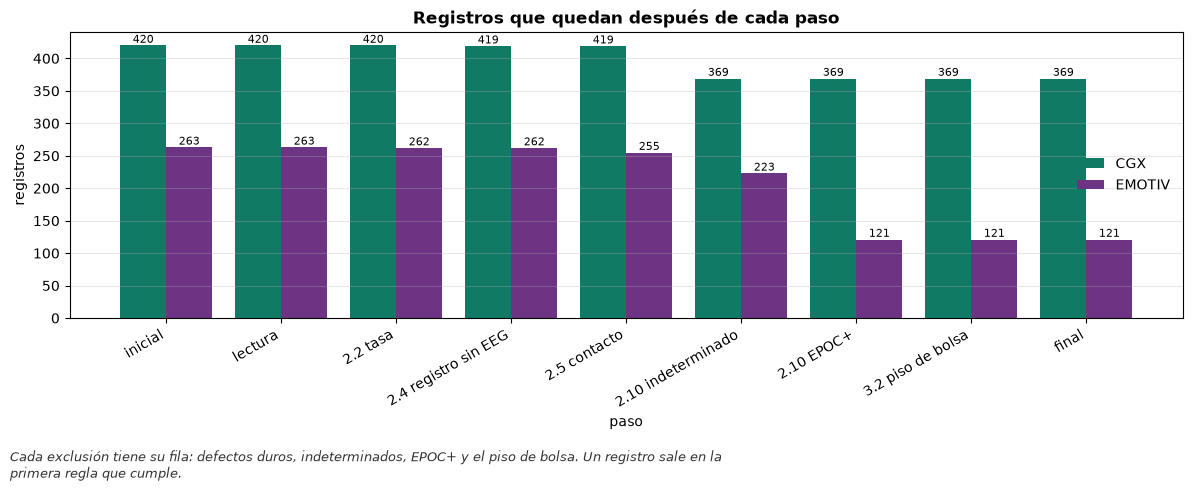

In [13]:
for family, flow in outputs["flows"].items():
    print(family)
    display(flow)
steps = outputs["flows"]["CGX"]["step"]
left = pd.DataFrame({f: outputs["flows"][f].set_index("step")["records_left"]
                     for f in ("CGX", "EMOTIV")}).loc[steps]
fig = audit_plots.grouped_bar(left, "Registros que quedan después de cada paso", "paso",
    "registros", "Cada exclusión tiene su fila: defectos duros, indeterminados, EPOC+ y el piso de "
    "bolsa. Un registro sale en la primera regla que cumple.",
    figsize=(12, 4.5))
audit_plots.save(fig, "03_2.10_flujo_registros", FIG); plt.show()

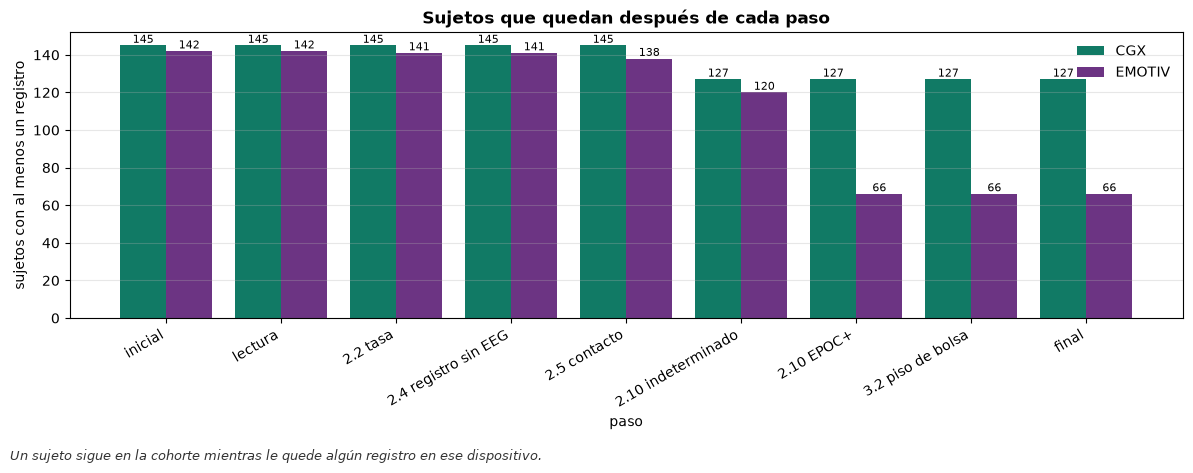

indeterminados excluidos: 84 registros de 20 sujetos


In [14]:
subjects = pd.DataFrame({f: outputs["flows"][f].set_index("step")["subjects_left"]
                         for f in ("CGX", "EMOTIV")}).loc[steps]
fig = audit_plots.grouped_bar(subjects, "Sujetos que quedan después de cada paso", "paso",
    "sujetos con al menos un registro", "Un sujeto sigue en la cohorte mientras le quede algún "
    "registro en ese dispositivo.", figsize=(12, 4.5))
audit_plots.save(fig, "03_2.10_flujo_sujetos", FIG); plt.show()
undetermined = manifest[manifest.undetermined]
assert undetermined.excluded.all()
print("indeterminados excluidos:", len(undetermined), "registros de",
      undetermined["subject"].nunique(), "sujetos")

## 2.10 — Las exclusiones cruzadas con etiqueta, sexo y edad

Cada tipo por separado, con su tabla: defectos duros, incompatibilidades, indeterminados, EPOC+ y piso de bolsa. Ninguna regla es una incompatibilidad, así que esa tabla se escribe y está vacía. El cruce de los indeterminados con la etiqueta es trivial por construcción; el que importa es el de EPOC+, porque saca registros sanos de un modelo entero. Un sujeto cuenta como excluido en una cohorte cuando alguno de sus registros en ella salió.

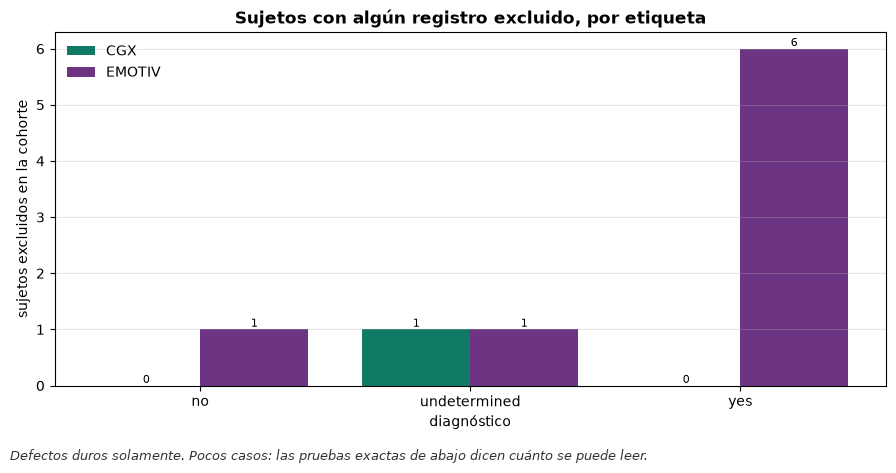

,family,value,total,median_age
5,CGX,excluded,1,7.0
6,CGX,kept,144,12.0
12,EMOTIV,excluded,8,10.0
13,EMOTIV,kept,134,12.0


,label_yes_vs_no_fisher_p,sex_fisher_p,age_mannwhitney_p
family,,,
CGX,1.000000,1.000000,0.133555
EMOTIV,0.419557,0.475425,0.039015


incompatibilidades excluidas: 0


by                         label                      sex      
value                         no undetermined   yes     F     M
kind                family                                     
bag_floor           CGX      0.0          0.0   0.0   0.0   0.0
                    EMOTIV   0.0          0.0   0.0   0.0   0.0
design_epocplus     CGX      0.0          0.0   0.0   0.0   0.0
                    EMOTIV   9.0          0.0  46.0  21.0  34.0
design_undetermined CGX      0.0         18.0   0.0  11.0   7.0
                    EMOTIV   0.0         18.0   0.0  12.0   6.0
hard_defect         CGX      0.0          1.0   0.0   0.0   1.0
                    EMOTIV   1.0          1.0   6.0   2.0   6.0
incompatibility     CGX      0.0          0.0   0.0   0.0   0.0
                    EMOTIV   0.0          0.0   0.0   0.0   0.0

label_yes_vs_no_fisher_p  sex_fisher_p  age_mannwhitney_p
kind            family                                                           
bag_floor       CGX                     1.000000      1.000000                NaN
                EMOTIV                  1.000000      1.000000                NaN
design_epocplus CGX                     1.000000      1.000000                NaN
                EMOTIV                  0.000121      0.728622           0.005701

In [15]:
crosses = outputs["crosses"]
hard = crosses[crosses.kind == "hard_defect"]
label = hard[hard.by == "label"].pivot_table(index="value", columns="family", values="excluded")
fig = audit_plots.grouped_bar(label, "Sujetos con algún registro excluido, por etiqueta",
    "diagnóstico", "sujetos excluidos en la cohorte",
    "Defectos duros solamente. Pocos casos: las pruebas exactas de abajo dicen cuánto se puede leer.")
audit_plots.save(fig, "03_2.10_exclusiones_por_etiqueta", FIG); plt.show()
tests = hard.groupby("family")[["label_yes_vs_no_fisher_p", "sex_fisher_p", "age_mannwhitney_p"]].first()
display(hard[hard.by == "age"][["family", "value", "total", "median_age"]])
display(tests)
print("incompatibilidades excluidas:",
      int(crosses.loc[crosses.kind == "incompatibility", "excluded"].fillna(0).sum()))
by_kind = crosses[crosses.by.isin(["label", "sex"])].pivot_table(
    index=["kind", "family"], columns=["by", "value"], values="excluded", aggfunc="sum")
display(by_kind)
design_tests = (crosses[crosses.kind.isin(["design_epocplus", "bag_floor"])]
                .groupby(["kind", "family"])[["label_yes_vs_no_fisher_p", "sex_fisher_p",
                                              "age_mannwhitney_p"]].first())
display(design_tests)

In [16]:
positive = {(f, t): p for f, row in tests.iterrows() for t, p in row.items() if p is not None and p < 0.05}
print("comprobaciones con p < 0.05:", positive or "ninguna")

comprobaciones con p < 0.05: {('EMOTIV', 'age_mannwhitney_p'): 0.039015323140379185}


## 4.2 — La partición en cuatro folds, congelada

Al terminar, el preprocesamiento toma los sujetos que sobreviven a todos sus pasos (al menos un registro conservado, en cualquier dispositivo) y los reparte en cuatro folds estratificados por etiqueta y por sexo, siempre por sujeto. En la rotación `r`, el fold `r` es prueba, el `(r + 1) mod 4` es validación y los otros dos son entrenamiento: cada fold es prueba una vez y validación una vez.

**Cuál es la vigente.** `MIL-CREDA/Partition/folds_4.json` es la partición en vigor, y es la única que leen este cuaderno, el punto de entrada y los módulos `bag_data`, `assignment` y `separability`: todos la toman de una sola constante, `partition.PARTITION_RELATIVE`. Guarda los folds por sujeto, las rotaciones, la huella de lo que la produjo (la lista ordenada de sobrevivientes con su etiqueta y su sexo, la semilla y el sha256 de `partition.py`) y su propio hash. En cada corrida se recalcula: si es idéntica sigue sin reescribir el archivo; si difiere, la celda de producción ya se detuvo con un error que dice qué cambió. Todo resultado que use la partición registra `partition_sha256`, y `partition.check_result` rechaza al cargarlo uno que no coincida con la vigente.

**Por qué son cuatro y por qué sigue `folds.json`.** El plan v40 (sección 4.2) bajó de cinco a cuatro folds por una medición: con cinco, el reparto de los comunes dejaba folds de prueba con un solo control del lado objetivo. La partición nueva se generó como la sección prevé, con la bandera explícita de regeneración y un nombre nuevo (`partition.freeze_partition(..., regenerate=True, new_name="folds_4.json")`), sobre los mismos 131 sobrevivientes y la misma semilla. Se llamó a la función del módulo y no al punto de entrada porque éste recalcula `Data/processed/`, que no depende de los folds; por eso la salida impresa de la celda de producción es la de su última corrida completa. La partición de cinco folds (`MIL-CREDA/Partition/folds.json`, hash `1de58db2…`) queda en el repositorio sin tocar, como registro de lo que usaron los resultados del plan v18; con el código actual no vale como vigente: `partition.check_current` la rechaza por su número de folds y `freeze_partition` por su versión de código.


In [17]:
doc = partition.check_current(built["partition"]["doc"])
assert PARTITION == REPOSITORY / partition.PARTITION_RELATIVE and PARTITION.name == "folds_4_v50.json"
survivors = partition.survivors(manifest)
assert sorted(doc["folds"]) == survivors.subject.tolist()
assert partition.current_partition_hash(PARTITION) == doc["partition_sha256"]
partition.check_result({"partition_sha256": doc["partition_sha256"]}, PARTITION)
print("sobrevivientes:", len(survivors), "| semilla:", doc["fingerprint"]["seed"],
      "| versión del código:", doc["fingerprint"]["code_version"][:12])
print("partition_sha256:", doc["partition_sha256"])
print("sha256 del archivo:", preprocess.file_sha256(PARTITION))
five = partition.load_partition(REPOSITORY / partition.FIVE_FOLD_RELATIVE)
print("partición de cinco folds conservada:", partition.FIVE_FOLD_RELATIVE, five["partition_sha256"],
      "| mismos sobrevivientes:", five["fingerprint"]["survivors"] == doc["fingerprint"]["survivors"])
display(survivors.groupby(["label", "sex"]).size().rename("sujetos").to_frame().T)
folds_by_stratum = partition.fold_table(doc)
display(folds_by_stratum)
partition.rotation_table(doc)


sobrevivientes: 131 | semilla: 20261025 | versión del código: e698b2d8a6ad
partition_sha256: abc9012bad78eaaa542c08a1e38e2f35d110e00f33739d76853624297d8735d1
sha256 del archivo: ee46d4d43eaa54fac14b9fa48b35df90c32590cd8b7c1a0239bb882a2af2fcdc
partición de cinco folds conservada: MIL-CREDA/Partition/folds.json 1de58db2307394de57d2ee853a350099e6492aa5470119a9cecb6633df165ad3 | mismos sobrevivientes: True


label    no     yes    
sex       F   M   F   M
sujetos  21  27  24  59

,no/F,no/M,yes/F,yes/M,total
fold,,,,,
0,6,6,6,15,33
1,5,7,6,15,33
2,5,7,6,15,33
3,5,7,6,14,32


,rotación,prueba,validación,entrenamiento,sujetos prueba,sujetos validación,sujetos entrenamiento
0,0,0,1,"[2, 3]",33,33,65
1,1,1,2,"[0, 3]",33,33,65
2,2,2,3,"[0, 1]",33,32,66
3,3,3,0,"[1, 2]",32,33,66


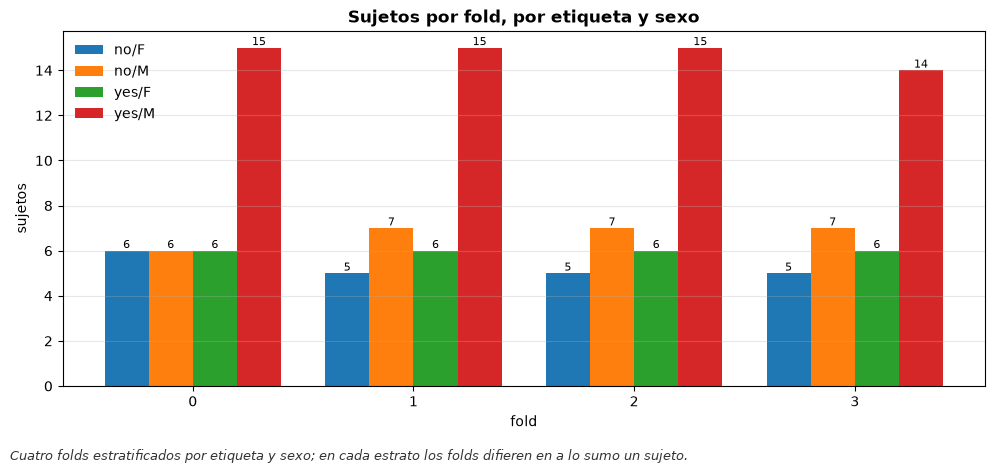

,sujetos con CGX,sujetos con EPOCX
fold,,
0,31,14
1,33,15
2,33,22
3,30,15


In [18]:
fig = audit_plots.grouped_bar(folds_by_stratum.drop(columns="total"),
    "Sujetos por fold, por etiqueta y sexo", "fold", "sujetos",
    "Cuatro folds estratificados por etiqueta y sexo; en cada estrato los folds difieren en a lo "
    "sumo un sujeto.", figsize=(10, 4.5))
audit_plots.save(fig, "03_4.2_folds_por_estrato", FIG); plt.show()
devices = (manifest[~manifest.excluded].assign(fold=lambda t: t.subject.map(doc["folds"]))
           .groupby(["fold", "device"]).subject.nunique().unstack(fill_value=0))
devices.columns = [f"sujetos con {c}" for c in devices.columns]
devices


### El manifiesto de hashes

Los datos procesados no van al repositorio. `MIL-CREDA/Manifests/processed_sha256.csv` sí: una fila por archivo bajo `MIL-CREDA/Data/processed/` con su tamaño y su sha256, para comprobar que una regeneración produjo los mismos bytes.


In [19]:
hashes = built["sha_manifest"]
print(len(hashes), "archivos;", f"{hashes['bytes'].sum() / 1e9:.2f} GB")
hashes.assign(carpeta=hashes.file.str.split("/").str[0].where(hashes.file.str.contains("/"), "(raíz)")
              ).groupby("carpeta").agg(archivos=("file", "count"), bytes=("bytes", "sum"))


1177 archivos; 2.78 GB


,archivos,bytes
carpeta,,
(raíz),4,196878
records,683,687474
signals,490,2774653571


## 4.3 y 5.1 — Bolsas, asignación de dominio por transferencia y separabilidad re-medida

Plan v40, secciones 3.2, 4.3, 4.6, 5.1–5.3 y 6.2. Esta sección no tiene lógica propia: llama a tres módulos del paquete, cada uno con sus pruebas.

| Paso | Módulo | Qué hace |
|---|---|---|
| 3.2 | `bag_data` | una bolsa por sujeto y condición, sólo con registros conservados; lleva sus ventanas, sus marcas, la etiqueta, el sexo y el fold de la partición congelada, que lee y verifica por su hash |
| 4.3, 4.6, 6.2 | `assignment` | por transferencia, una función total que lleva cada sujeto a fuente, objetivo o excluido, fija en las cuatro rotaciones; la sonda, el agrupado por par y la regla de elegibilidad |
| 5.1 | `separability` | la separabilidad entre dominios con el instrumento de la auditoría, por rotación, y la regla núcleo/control |

**Las condiciones.** Brazo de nivel: los tres niveles de Slackline en CGX, cada uno su propia condición. Brazo de tarea: Robots y CogniFit en EPOC X. Brazo de dispositivo: el nivel medio de Slackline en CGX (L6) y Robots en EPOC X. EPOC+ no tiene bolsas: salió en el preprocesamiento.

**La regla de asignación.** Un sujeto con una sola de las dos condiciones va a ese lado; uno sin ninguna queda excluido. Los que tienen las dos (los comunes) se reparten para que, dentro de cada fold y para cada diagnóstico por separado, fuente y objetivo queden del tamaño más parejo posible, en el orden que fija la semilla de partición. La regla es la misma en los tres brazos: la igualación es por clase y no por el tamaño total del lado. En el brazo de dispositivo eso manda los comunes con diagnóstico al lado de bajo costo (EPOC X), porque los que solo tienen CGX son casi todos con diagnóstico, y reparte los controles comunes entre los dos lados; el caso especial del plan v38, todos los comunes al lado EPOC X, dejaba un solo control del lado CGX en algún fold. La regla depende del par de condiciones y no de la dirección, así que A→B y B→A leen la misma condición de cada sujeto. La intersección entre fuente y objetivo vacía es una aserción que se comprueba en cada transferencia y en cada rotación.

**La sonda (6.2).** En cada rotación, los comunes del fold de prueba. Su otra condición sólo se alcanza con `assignment.probe_bag`, que rechaza a cualquier otro sujeto; cada común pasa por la sonda exactamente una vez en las cuatro rotaciones.

**El agrupado por par (4.6).** El contraste principal de un par núcleo junta sus dos direcciones. Como la asignación del par es una sola con los lados invertidos, entre las dos direcciones cada sujeto asignado es objetivo exactamente una vez; `assignment.pair_pool` devuelve, para cada sujeto, la dirección en la que es objetivo, y falla con una aserción si alguno aparece dos veces o ninguna.

In [20]:
from MIL_CREDA_EEG import assignment, bag_data, separability

assert bag_data.default_partition_path() == PARTITION
bags = bag_data.load_bags(OUT, PARTITION,
                          expected_partition_sha256=partition.current_partition_hash(PARTITION))
assignments = [assignment.assign_from_bags(t, bags) for t in assignment.TRANSFERS]
print("bolsas:", len(bags.bags), "| partition_sha256:", bags.partition_sha256)
display(pd.DataFrame({c: [len(bags.holders(c))] for c in bag_data.CONDITIONS},
                     index=["sujetos con bolsa"]))
sizes = assignment.size_table(assignments)
fixed = sizes.drop_duplicates("transfer").set_index(["arm", "transfer"])[
    ["source", "target", "excluded", "commons"]]
display(fixed)
sizes.pivot_table(index=["arm", "transfer"], columns="rotation", sort=False,
                  values=["source_train", "target_train", "target_test", "probe"])

bolsas: 490 | partition_sha256: abc9012bad78eaaa542c08a1e38e2f35d110e00f33739d76853624297d8735d1


,L1,L6,L11,Robots,CogniFit
sujetos con bolsa,123,123,123,60,61


source  target  excluded  commons
arm    transfer                                           
level  L1->L6                63      63         5      120
       L1->L11               63      64         4      119
       L6->L1                63      63         5      120
       L6->L11               62      63         6      121
       L11->L1               64      63         4      119
       L11->L6               63      62         6      121
task   Robots->CogniFit      33      33        65       55
       CogniFit->Robots      33      33        65       55
device L6->Robots            75      52         4       56
       Robots->L6            52      75         4       56

source_train                   target_train                   target_test                   probe                  
rotation                           0     1     2     3            0     1     2     3           0     1     2     3     0     1     2     3
arm    transfer                                                                                                                            
level  L1->L6                   31.0  30.0  32.0  33.0         31.0  31.0  32.0  32.0        16.0  16.0  16.0  15.0  28.0  31.0  32.0  29.0
       L1->L11                  31.0  30.0  32.0  33.0         32.0  31.0  32.0  33.0        15.0  17.0  16.0  16.0  28.0  31.0  32.0  28.0
       L6->L1                   31.0  31.0  32.0  32.0         31.0  30.0  32.0  33.0        15.0  17.0  16.0  15.0  28.0  31.0  32.0  29.0
       L6->L11                  31.0  30.0  31.0  32.0         32.0  30.0  31.0  33.0        15.0  16.0  17.0  15.0  30.0  30.0  32.0  29.0
       L11->L1                  32.0  31.0  32.0  33.0         31.0  30.0  32.0  33.0        16.0  16.0  17.0  14.0  28.0  31.0  32.0  28.0
       L11->L6                  32.0  30.0  31.0  33.0         31.0  30.0  31.0  32.0        15.0  16.0  16.0  15.0  30.0  30.0  32.0  29.0
task   Robots->CogniFit         19.0  15.0  14.0  18.0         18.0  14.0  15.0  19.0         7.0   8.0  11.0   7.0  12.0  11.0  19.0  13.0
       CogniFit->Robots         18.0  14.0  15.0  19.0         19.0  15.0  14.0  18.0         7.0   7.0  11.0   8.0  12.0  11.0  19.0  13.0
device L6->Robots               33.0  39.0  42.0  36.0         30.0  23.0  22.0  29.0         9.0  13.0  16.0  14.0  12.0  11.0  20.0  13.0
       Robots->L6               30.0  23.0  22.0  29.0         33.0  39.0  42.0  36.0        22.0  20.0  16.0  17.0  12.0  11.0  20.0  13.0

In [21]:
# Sec. 4.3: leída por lado, cada lado necesita al menos cinco sujetos por clase en cada fold.
reports = [assignment.eligibility(a) for a in assignments]
display(pd.DataFrame([{"brazo": e["arm"], "transferencia": e["transfer"], "cumple": e["passes"],
                       "mínimo observado": e["min_count"], "mínimo exigido": e["minimum"],
                       "celdas bajo el mínimo": len(e["failing"]),
                       **{f"mín. {side} {label}": n for side in ("source", "target")
                          for label, n in e["min_per_fold"][side].items()},
                       **{f"objetivo {label}": n for label, n in e["pooled_target"].items()}}
                      for e in reports]))
# Sec. 4.6: cada par con sus dos direcciones juntas; cada sujeto asignado es objetivo una sola vez.
pair_rows = []
for a, b in assignment.pairs(assignments):
    pooled = assignment.pair_pool(a, b)
    totals = assignment.pair_totals(a, b)
    pair_rows.append({"brazo": totals["arm"], "par": totals["pair"], "sujetos agrupados": len(pooled),
                      **{f"objetivo {label}": n for label, n in totals["pooled_target"].items()}})
display(pd.DataFrame(pair_rows))
cells = pd.concat([e["table"] for e in reports])
cells.pivot_table(index=["arm", "transfer", "side"], columns=["label", "fold"], values="n",
                  sort=False)


,brazo,transferencia,cumple,mínimo observado,mínimo exigido,celdas bajo el mínimo,mín. source no,mín. source yes,mín. target no,mín. target yes,objetivo no,objetivo yes
0,level,L1->L6,True,5,5,0,5,9,5,10,22,41
1,level,L1->L11,True,5,5,0,5,9,5,10,23,41
2,level,L6->L1,True,5,5,0,5,10,5,9,23,40
3,level,L6->L11,False,4,5,1,4,9,5,10,22,41
4,level,L11->L1,True,5,5,0,5,10,5,9,22,41
5,level,L11->L6,False,4,5,1,5,10,4,9,22,40
6,task,Robots->CogniFit,False,2,5,9,3,2,3,2,16,17
7,task,CogniFit->Robots,False,2,5,9,3,2,3,2,17,16
8,device,L6->Robots,False,4,5,1,5,10,5,4,23,29
9,device,Robots->L6,False,4,5,1,5,4,5,10,22,53


,brazo,par,sujetos agrupados,objetivo no,objetivo yes
0,device,L6|Robots,127,45,82
1,level,L1|L11,127,45,82
2,level,L1|L6,126,45,81
3,level,L11|L6,125,44,81
4,task,CogniFit|Robots,66,33,33


label                            no   yes   no   yes   no   yes   no   yes
fold                              0     0    1     1    2     2    3     3
arm    transfer         side                                              
level  L1->L6           source  5.0  10.0  6.0  11.0  6.0  10.0  6.0   9.0
                        target  5.0  11.0  6.0  10.0  6.0  10.0  5.0  10.0
       L1->L11          source  5.0  11.0  6.0  10.0  6.0  11.0  5.0   9.0
                        target  5.0  10.0  6.0  11.0  6.0  10.0  6.0  10.0
       L6->L1           source  5.0  11.0  6.0  10.0  6.0  10.0  5.0  10.0
                        target  5.0  10.0  6.0  11.0  6.0  10.0  6.0   9.0
       L6->L11          source  4.0  11.0  6.0  10.0  6.0  10.0  6.0   9.0
                        target  5.0  10.0  6.0  10.0  6.0  11.0  5.0  10.0
       L11->L1          source  5.0  10.0  6.0  11.0  6.0  10.0  6.0  10.0
                        target  5.0  11.0  6.0  10.0  6.0  11.0  5.0   9.0
       L11->L6          source  5.0  10.0  6.0  10.0  6.0  11.0  5.0  10.0
                        target  4.0  11.0  6.0  10.0  6.0  10.0  6.0   9.0
task   Robots->CogniFit source  5.0   2.0  3.0   4.0  5.0   6.0  4.0   4.0
                        target  5.0   2.0  3.0   5.0  5.0   6.0  3.0   4.0
       CogniFit->Robots source  5.0   2.0  3.0   5.0  5.0   6.0  3.0   4.0
                        target  5.0   2.0  3.0   4.0  5.0   6.0  4.0   4.0
device L6->Robots       source  5.0  17.0  6.0  14.0  6.0  10.0  5.0  12.0
                        target  5.0   4.0  6.0   7.0  6.0  10.0  6.0   8.0
       Robots->L6       source  5.0   4.0  6.0   7.0  6.0  10.0  6.0   8.0
                        target  5.0  17.0  6.0  14.0  6.0  10.0  5.0  12.0

### 5.1 — Separabilidad entre dominios, re-medida con sujetos disjuntos

El mismo instrumento de la auditoría (`audit_domains`): potencia por banda en escala logarítmica (delta, theta, alfa, beta y gamma baja, Welch de 2 s) por canal, mediana sobre las ventanas de la bolsa; regresión logística L2 con imputación y estandarización dentro del fold de entrenamiento; validación interna `StratifiedGroupKFold(5)` agrupada por sujeto, la de la auditoría; 200 permutaciones de la etiqueta de dominio dentro del diseño agrupado; semilla 20261025. Sólo cambia la composición de sujetos. Las características salen de las ventanas de cada bolsa, que son la señal que la auditoría calculaba desde el crudo (filtro 0,2–45 Hz sobre el registro continuo, 128 Hz, sin la primera ventana ni la parcial final).

**Qué se compara.** Por transferencia y rotación, los sujetos fuente de los dos folds de entrenamiento de esa rotación contra los sujetos objetivo de esos mismos folds, cada uno en la condición que la asignación lee para él. Es exactamente lo que ve la adaptación: los sujetos de validación y de prueba de los dos lados no entran. Como la asignación es una sola función por par de condiciones, las dos direcciones de un par usan los mismos sujetos con las etiquetas de dominio intercambiadas, y por eso la regla las promedia. Dos lecturas: todos los sujetos y dentro de cada clase. El brazo de nivel usa el montaje CGX completo, el de tarea el Emotiv completo, y el de dispositivo los doce canales que los dos montajes nombran igual, sólo para medir. Se reporta la media y el desvío sobre las cuatro rotaciones.

**La regla núcleo/control, declarada antes de medir.** La separabilidad de un par es la media de sus dos direcciones (lectura de todos los sujetos). En cada brazo el par con la mayor separabilidad es núcleo, con sus dos transferencias, y los demás son control. Los brazos de tarea y de dispositivo tienen un solo par: sus dos transferencias son núcleo.

`RUN_SEPARABILITY = True` recalcula todo y reescribe `MIL-CREDA/Results/separability/` (unos dos minutos y medio con cuatro procesos); en `False` se leen las tablas guardadas, que se rechazan si su hash de partición no es el vigente.

In [22]:
RUN_SEPARABILITY = False
SEPARABILITY = REPOSITORY / separability.RESULTS_RELATIVE
if RUN_SEPARABILITY:
    separability.run(bags, SEPARABILITY, workers=WORKERS)
stored = separability.load_results(SEPARABILITY, PARTITION)
summary = stored["summary"]
print("partition_sha256 de los resultados:", summary["partition_sha256"])
print("permutaciones:", summary["instrument"]["n_permutations"],
      "| tiempo de la corrida guardada:", summary["timing"]["wall_seconds"], "s con",
      summary["timing"]["workers"], "procesos")
print("núcleo: ", summary["core"])
print("control:", summary["control"])
table = stored["table"]
auc = table.pivot_table(index=["arm", "pair", "pair_auc", "role", "transfer"], columns="reading",
                        values=["auc_rotation_mean", "auc_rotation_sd", "perm_p_median"])
auc.reindex(columns=["all", "yes", "no"], level=1).round(3)

partition_sha256 de los resultados: abc9012bad78eaaa542c08a1e38e2f35d110e00f33739d76853624297d8735d1
permutaciones: 200 | tiempo de la corrida guardada: 147.4 s con 4 procesos
núcleo:  {'device': ['L6->Robots', 'Robots->L6'], 'level': ['L1->L11', 'L11->L1'], 'task': ['CogniFit->Robots', 'Robots->CogniFit']}
control: {'device': [], 'level': ['L1->L6', 'L11->L6', 'L6->L1', 'L6->L11'], 'task': []}


auc_rotation_mean               auc_rotation_sd               perm_p_median              
reading                                                                all    yes     no             all    yes     no           all    yes     no
arm    pair            pair_auc role    transfer                                                                                                  
device L6|Robots       0.951964 core    L6->Robots                   0.952  0.975  0.921           0.007  0.042  0.063         0.005  0.005  0.025
                                        Robots->L6                   0.952  0.975  0.921           0.007  0.042  0.063         0.005  0.005  0.017
level  L11|L6          0.393006 control L11->L6                      0.393  0.498  0.392           0.096  0.114  0.095         0.818  0.595  0.719
                                        L6->L11                      0.393  0.500  0.392           0.095  0.114  0.095         0.831  0.585  0.721
       L1|L11          0.570607 core    L1->L11                      0.571  0.542  0.650           0.030  0.071  0.053         0.274  0.420  0.221
                                        L11->L1                      0.571  0.541  0.650           0.030  0.073  0.053         0.249  0.453  0.182
       L1|L6           0.538591 control L1->L6                       0.538  0.441  0.417           0.050  0.151  0.158         0.343  0.689  0.781
                                        L6->L1                       0.539  0.443  0.417           0.049  0.149  0.158         0.294  0.657  0.746
task   CogniFit|Robots 0.707639 core    CogniFit->Robots             0.708  0.750  0.625           0.090  0.191  0.290         0.132  0.119  0.338
                                        Robots->CogniFit             0.708  0.750  0.625           0.090  0.191  0.290         0.129  0.132  0.368

**Lectura de esta sección** (partición de cuatro folds, `partition_sha256` `abc9012b…`).

* **Núcleo y control.** Brazo de nivel: el par L1–L11 es el de mayor separabilidad (0,571), por encima de L1–L6 (0,539) y L6–L11 (0,393); sus dos transferencias son núcleo y las otras cuatro son control. Es el mismo núcleo que con cinco folds. La diferencia con L1–L6 sigue siendo chica y ninguno de los dos pares se distingue del azar por permutación: la p mediana sobre las rotaciones es de 0,27 y 0,25 en las dos direcciones del par núcleo y de 0,34 y 0,29 en las de L1–L6; la regla se declaró para aplicarse igual. L6–L11 queda por debajo de 0,5 en las cuatro rotaciones (desvío 0,10): el clasificador acierta menos que el azar al separar esos dos dominios, una lectura que se reporta y que la regla no usa. Brazo de tarea: 0,708 (p mediana 0,13). Brazo de dispositivo: 0,952 (p mediana 0,005). Las dos direcciones de cada par dan la misma área bajo la curva, porque usan los mismos sujetos; sólo la p de permutación difiere levemente.
* **Fuente en entrenamiento por rotación.** Nivel: entre 30 y 33 sujetos fuente en los dos folds de entrenamiento. Tarea: entre 14 y 19. Dispositivo: entre 33 y 42 con L6 como fuente y entre 22 y 30 con Robots como fuente.
* **Elegibilidad por lado (4.3).** Con cuatro folds y la igualación por clase, el mínimo de controles por fold del lado objetivo es de 4 o 5 en el brazo de nivel, de 5 en el de dispositivo y de 3 en el de tarea; el de sujetos con diagnóstico es de 9 o 10 en nivel, de 2 en tarea y de 4 del lado EPOC X en dispositivo. Leída por lado, la regla de cinco por clase por fold se cumple en las cuatro transferencias de los pares L1–L6 y L1–L11 y no en las otras seis: en L6–L11 queda una celda con 4 controles (fold 0), en dispositivo una con 4 sujetos con diagnóstico del lado EPOC X (fold 0), y en tarea nueve celdas por dirección bajo el mínimo, con 2 sujetos con diagnóstico en el fold 0. Se reporta; esta sección no excluye nada.
* **Totales del objetivo (4.6).** Por transferencia, TDAH/control: nivel 40–41/22–23; tarea 16–17/16–17; dispositivo L6→Robots 29/23 y Robots→L6 53/22. Por par, con las dos direcciones juntas y cada sujeto objetivo una sola vez: L1–L11 82/45, L1–L6 81/45, L6–L11 81/44, Robots–CogniFit 33/33, L6–Robots 82/45.


## Lectura

* **Defectos duros, sin cambios.** Las tres reglas seleccionan exactamente los registros que la auditoría y el plan nombran: UB0058 nivel 6 en CGX (sin EEG), UB0095 Robots EPOC X por tasa, y los ocho de la regla de contacto, uno de los cuales es ese mismo UB0095. Salen 9 registros: 1 de 420 en CGX y 8 de 263 en Emotiv. La comprobación de edad de la sección 2.10 sigue positiva y se declara: en Emotiv los sujetos excluidos por defecto son más chicos que los conservados (mediana 10 contra 12 años, Mann-Whitney p ≈ 0,04, 8 sujetos). Con la etiqueta y con el sexo no hay asociación.
* **Indeterminados (2.10).** Salen los 20 sujetos con diagnóstico indeterminado y sus 84 registros: 82 salen en esa fila (50 CGX, 32 Emotiv) y los otros 2, de UB0058, ya habían salido por defecto.
* **EPOC+ (2.10).** 118 registros son del modelo EPOC+; 102 salen en esa fila y los otros 16 ya habían salido antes (indeterminados o contacto). De los 63 sujetos que aportaban EPOC+, 51 siguen en el conjunto con sus otros registros (148 CGX y 1 EPOC X); ningún registro EPOC+ queda.
* **La comprobación de la sección 2.10 resulta positiva para EPOC+ y se declara.** Los sujetos que pierden registros EPOC+ son casi todos diagnosticados: 46 contra 9 (Fisher p ≈ 0,0001), y difieren en edad (Mann-Whitney p ≈ 0,006); con el sexo no hay asociación (p ≈ 0,73). Es la razón misma de la exclusión: el modelo EPOC+ no alcanza el balance de clases que exige la sección 4.3. La consecuencia también se declara: la cohorte Emotiv final es solo EPOC X (121 registros de 66 sujetos) y su composición no es la que describe el data paper.
* **Piso de bolsa (3.2).** No excluye ninguna bolsa. La más chica conservada tiene 68 ventanas en Robots, 75 en cada nivel de Slackline y 406 en Cognifit, las cifras que el plan declara. Queda como guarda.
* **Lo que queda.** 490 registros de 683 (369 CGX de 127 sujetos y 121 EPOC X de 66 sujetos), 66 393 ventanas. Sobreviven 131 sujetos (no/F 21, no/M 27, yes/F 24, yes/M 59), repartidos en cuatro folds de 33, 33, 33 y 32; en cada estrato los folds difieren en a lo sumo un sujeto. El hash de la partición vigente (`folds_4.json`) es `abc9012bad78eaaa542c08a1e38e2f35d110e00f33739d76853624297d8735d1`; el de la de cinco folds que se conserva (`folds.json`) es `1de58db2307394de57d2ee853a350099e6492aa5470119a9cecb6633df165ad3`.
* El borde de 45 Hz es el de un Butterworth de fase cero, no una pared: en el ejemplo CGX la banda 49–51 Hz conserva cerca del 9 % de su potencia; el EPOC X a 128 Hz ya venía filtrado por el dispositivo. La banda 8–12 Hz queda intacta.
* Nada de esto toca la señal: las marcas son datos laterales y las ventanas marcadas siguen en la bolsa.


In [23]:
size = sum(p.stat().st_size for p in OUT.rglob("*") if p.is_file())
print(f"tamaño en disco de MIL-CREDA/Data/processed: {size / 1e9:.2f} GB")

tamaño en disco de MIL-CREDA/Data/processed: 2.78 GB
